
# 🔔 The Central Limit Theorem (CLT)


**Learning Objectives**
- Understand what the Central Limit Theorem (CLT) states
- Visualize the difference between a *population* distribution and a *sampling distribution of the mean*
- Observe how sample size affects the shape of the sampling distribution
- Verify the relationship between population std, sample size, and standard error

---

## What does the CLT say?

> Given a population with **any** distribution (even a skewed one!), the sampling distribution of the **sample mean** will approach a **Normal distribution** as the sample size `n` increases — regardless of the population's original shape.

Formally, if $X_1, X_2, \dots, X_n$ are i.i.d. samples from a population with mean $\mu$ and standard deviation $\sigma$, then for large $n$:

$$\bar{X} \sim N\left(\mu, \frac{\sigma}{\sqrt{n}}\right)$$

The term $\frac{\sigma}{\sqrt{n}}$ is called the **Standard Error (SE)** of the mean.

We'll demonstrate this using the **`tips`** dataset, which has a noticeably **skewed** distribution.


## 1. Setup & Load Data

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")
%matplotlib inline
np.random.seed(42)

df = sns.load_dataset("tips")
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4



## 2. The "Population" Distribution

For this exercise, let's treat the entire `total_bill` column (244 records) as our **population**. Notice its shape — it's **right-skewed**, NOT normal.


Population size       : 244
Population mean (μ)   : 19.786
Population std (σ)    : 8.884


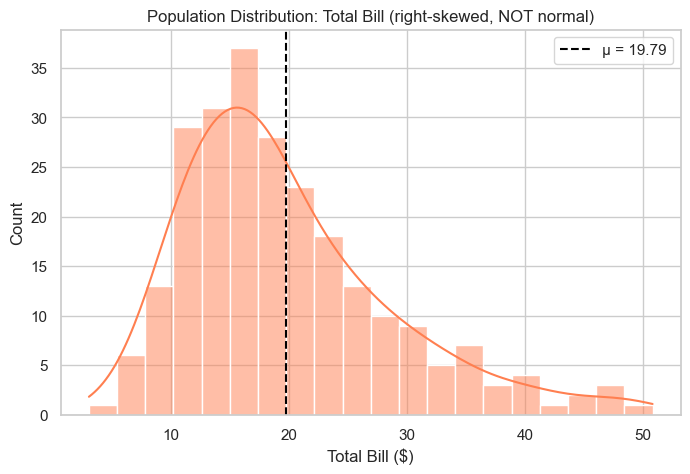

In [2]:
population = df["total_bill"].values

pop_mean = population.mean()
pop_std = population.std(ddof=0)  # population standard deviation

print(f"Population size       : {len(population)}")
print(f"Population mean (μ)   : {pop_mean:.3f}")
print(f"Population std (σ)    : {pop_std:.3f}")

plt.figure(figsize=(8, 5))
sns.histplot(population, bins=20, kde=True, color="coral")
plt.axvline(pop_mean, color="black", linestyle="--", label=f"μ = {pop_mean:.2f}")
plt.title("Population Distribution: Total Bill (right-skewed, NOT normal)")
plt.xlabel("Total Bill ($)")
plt.legend()
plt.show()


## 3. Drawing a Single Sample

Suppose we don't have access to the whole population — we can only collect a **sample**. Let's draw one random sample of size `n=30` and compute its mean.


In [3]:
n = 30
sample = np.random.choice(population, size=n, replace=True)
sample_mean = sample.mean()

print(f"Sample (first 10 values): {np.round(sample[:10], 2)}")
print(f"Sample mean (n={n})     : {sample_mean:.3f}")
print(f"Population mean (μ)     : {pop_mean:.3f}")
print(f"Difference              : {abs(sample_mean - pop_mean):.3f}")

Sample (first 10 values): [44.3  34.63  5.75 14.83 20.49 17.07 18.15 17.92 44.3  13.42]
Sample mean (n=30)     : 20.938
Population mean (μ)     : 19.786
Difference              : 1.152



A single sample mean is just **one estimate** of the population mean — it has some random error. What if we repeat this process thousands of times and look at the *distribution of sample means*? That's the **sampling distribution**.



## 4. Building the Sampling Distribution of the Mean

We'll repeat the process:
1. Draw a random sample of size `n` from the population (with replacement)
2. Compute its mean
3. Repeat this **1000 times**
4. Plot the distribution of these 1000 sample means


In [4]:
def sampling_distribution(population, n, n_simulations=1000, seed=42):
    # Returns an array of sample means, each computed from a random
    # sample of size n drawn (with replacement) from `population`.
    rng = np.random.default_rng(seed)
    means = np.empty(n_simulations)
    for i in range(n_simulations):
        sample = rng.choice(population, size=n, replace=True)
        means[i] = sample.mean()
    return means

sample_means_30 = sampling_distribution(population, n=30, n_simulations=1000)

print(f"Mean of sample means        : {sample_means_30.mean():.3f}")
print(f"Std dev of sample means (SE): {sample_means_30.std():.3f}")
print(f"Population mean (μ)         : {pop_mean:.3f}")
print(f"Theoretical SE (σ/√n)       : {pop_std/np.sqrt(30):.3f}")

Mean of sample means        : 19.797
Std dev of sample means (SE): 1.650
Population mean (μ)         : 19.786
Theoretical SE (σ/√n)       : 1.622


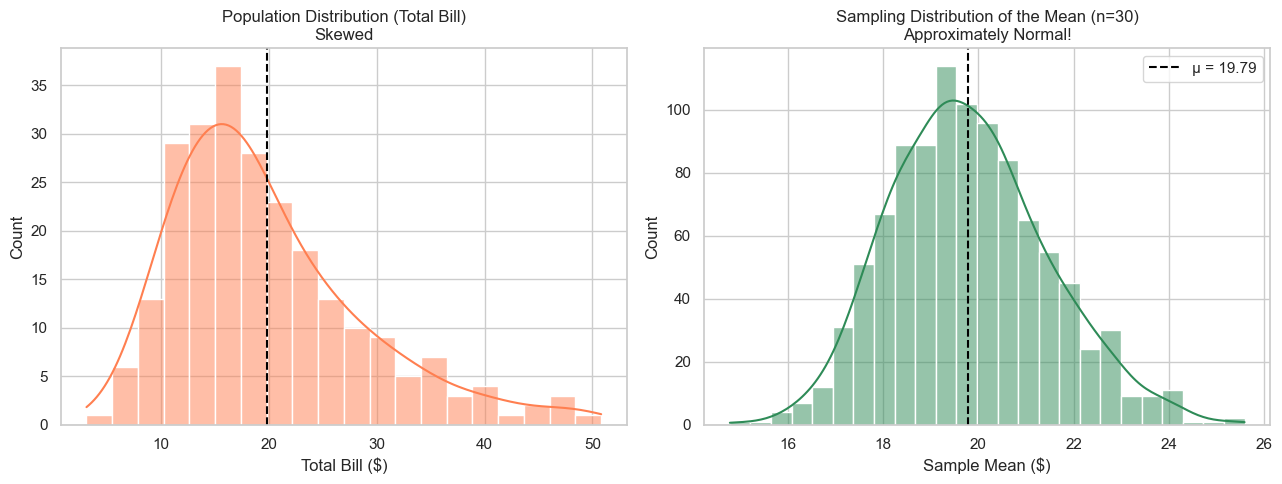

In [5]:
# Visualize: Population vs Sampling Distribution of the Mean
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(population, bins=20, kde=True, color="coral", ax=axes[0])
axes[0].axvline(pop_mean, color="black", linestyle="--")
axes[0].set_title("Population Distribution (Total Bill)\nSkewed")
axes[0].set_xlabel("Total Bill ($)")

sns.histplot(sample_means_30, bins=25, kde=True, color="seagreen", ax=axes[1])
axes[1].axvline(pop_mean, color="black", linestyle="--", label=f"μ = {pop_mean:.2f}")
axes[1].set_title("Sampling Distribution of the Mean (n=30)\nApproximately Normal!")
axes[1].set_xlabel("Sample Mean ($)")
axes[1].legend()

plt.tight_layout()
plt.show()


**Observe:** Even though the *population* is skewed, the distribution of *sample means* is much more symmetric and bell-shaped — this is the CLT in action!



## 5. Effect of Sample Size (n) on the Sampling Distribution

Let's repeat the experiment with different sample sizes: **n = 2, 5, 30, 100**. We expect:
- Larger `n` → sampling distribution becomes **more normal** and **narrower** (less variable)


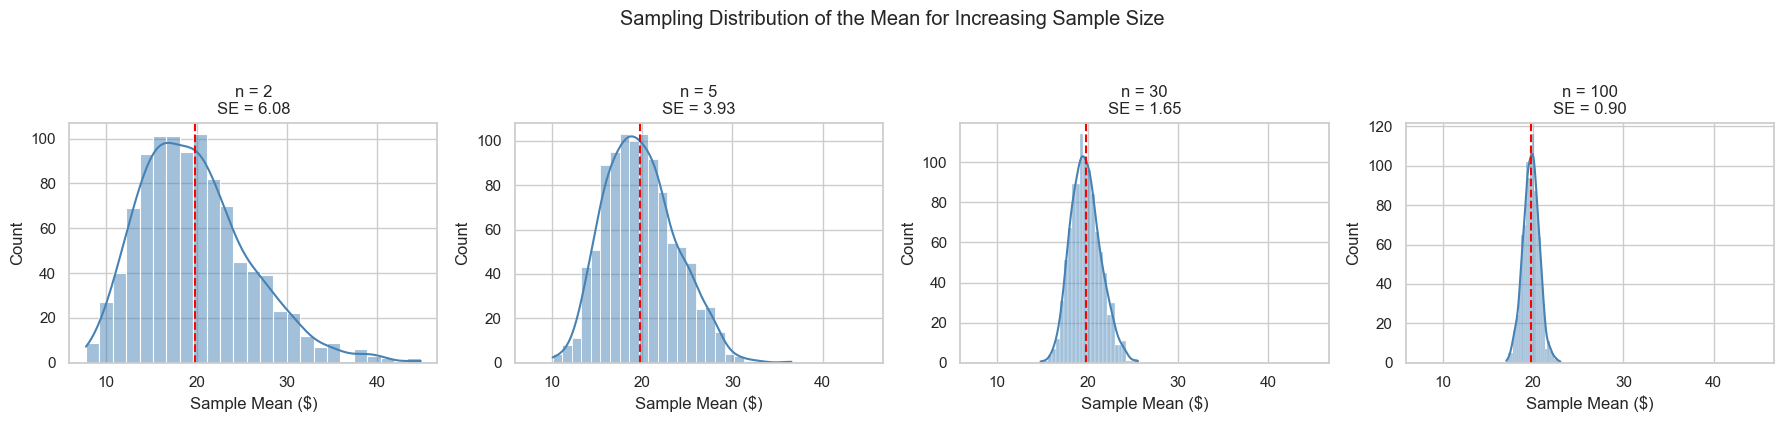

In [6]:
sample_sizes = [2, 5, 30, 100]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True)

for ax, n in zip(axes, sample_sizes):
    means = sampling_distribution(population, n=n, n_simulations=1000)
    sns.histplot(means, bins=25, kde=True, color="steelblue", ax=ax)
    ax.axvline(pop_mean, color="red", linestyle="--")
    ax.set_title(f"n = {n}\nSE = {means.std():.2f}")
    ax.set_xlabel("Sample Mean ($)")

plt.suptitle("Sampling Distribution of the Mean for Increasing Sample Size", y=1.05)
plt.tight_layout()
plt.show()


**Discussion points:**
- For **n = 2**, the sampling distribution is still quite skewed and spread out — it closely resembles the population shape.
- As **n increases (5 → 30 → 100)**, the distribution becomes increasingly **bell-shaped (normal)** and **narrower**.
- This holds true **regardless of the population's original shape** — that's the power of the CLT!



## 6. Standard Error and the $\sqrt{n}$ Relationship

The **Standard Error (SE)** of the sample mean is:

$$SE = \frac{\sigma}{\sqrt{n}}$$

This means: to **halve** the standard error (i.e., make estimates twice as precise), you need to **quadruple** the sample size!

Let's verify this relationship empirically.


In [7]:
results = []
for n in [2, 5, 10, 30, 50, 100, 200]:
    means = sampling_distribution(population, n=n, n_simulations=2000)
    empirical_se = means.std()
    theoretical_se = pop_std / np.sqrt(n)
    results.append([n, empirical_se, theoretical_se])

results_df = pd.DataFrame(results, columns=["Sample Size (n)", "Empirical SE", "Theoretical SE (σ/√n)"])
results_df

,Sample Size (n),Empirical SE,Theoretical SE (σ/√n)
0,2,6.306640,6.282043
1,5,3.905869,3.973113
2,10,2.829258,2.809415
3,30,1.616207,1.622017
4,50,1.251811,1.256409
5,100,0.885142,0.888415
6,200,0.631790,0.628204


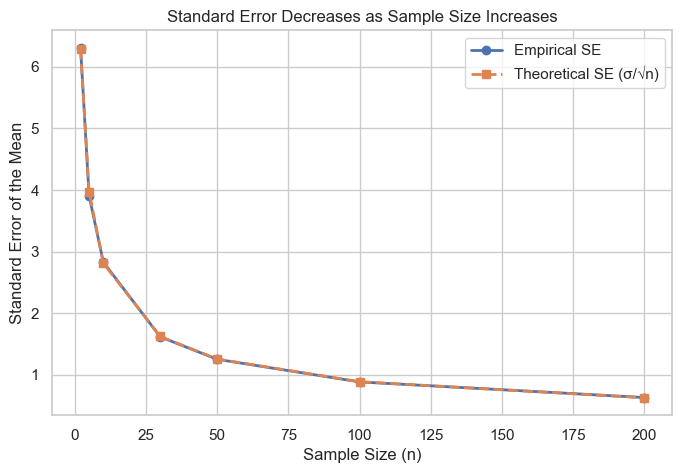

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(results_df["Sample Size (n)"], results_df["Empirical SE"], "o-", label="Empirical SE", linewidth=2)
plt.plot(results_df["Sample Size (n)"], results_df["Theoretical SE (σ/√n)"], "s--", label="Theoretical SE (σ/√n)", linewidth=2)
plt.xlabel("Sample Size (n)")
plt.ylabel("Standard Error of the Mean")
plt.title("Standard Error Decreases as Sample Size Increases")
plt.legend()
plt.show()


## 7. CLT Applies Even to Extremely Non-Normal Populations

To drive the point home, let's try an extreme case: a population that is **Bernoulli distributed** (only 0s and 1s) — using `titanic`'s `survived` column. This is about as "non-normal" as a distribution can get!


Population (Bernoulli) mean: 0.384
Population (Bernoulli) std : 0.486


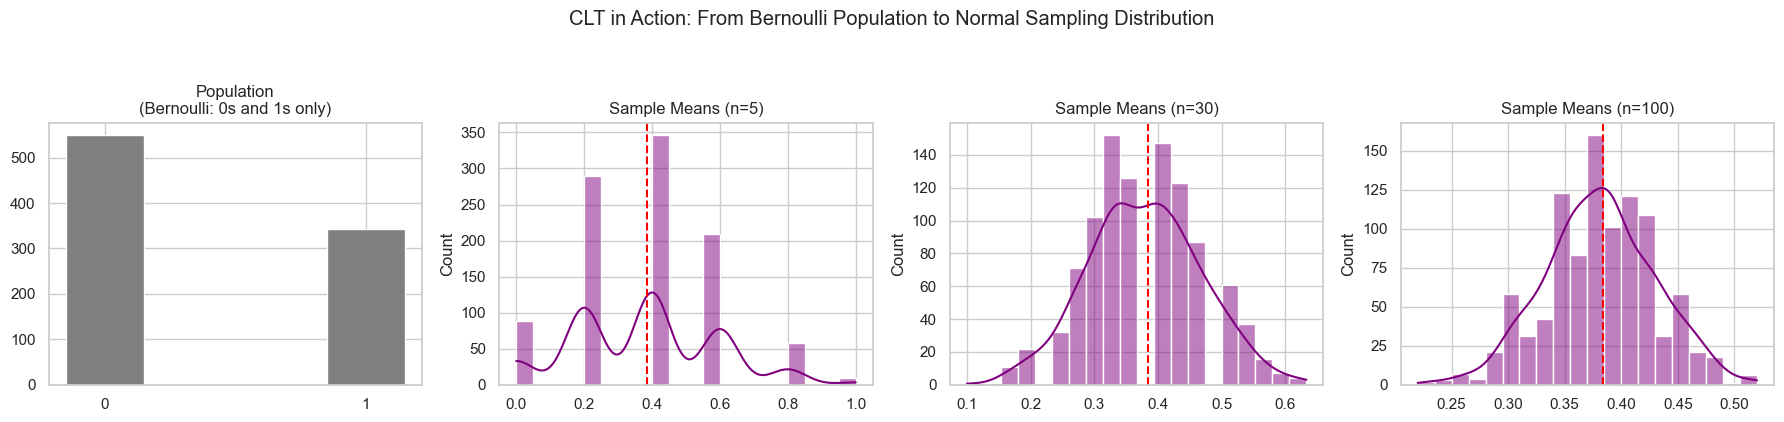

In [9]:
titanic = sns.load_dataset("titanic")
binary_population = titanic["survived"].dropna().values

p = binary_population.mean()
print(f"Population (Bernoulli) mean: {p:.3f}")
print(f"Population (Bernoulli) std : {binary_population.std():.3f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

# Original population (just two bars: 0 and 1)
axes[0].hist(binary_population, bins=[-0.25, 0.25, 0.75, 1.25], color="gray", rwidth=0.6)
axes[0].set_xticks([0, 1])
axes[0].set_title("Population\n(Bernoulli: 0s and 1s only)")

for ax, n in zip(axes[1:], [5, 30, 100]):
    means = sampling_distribution(binary_population, n=n, n_simulations=1000)
    sns.histplot(means, bins=20, kde=True, color="purple", ax=ax)
    ax.axvline(p, color="red", linestyle="--")
    ax.set_title(f"Sample Means (n={n})")

plt.suptitle("CLT in Action: From Bernoulli Population to Normal Sampling Distribution", y=1.05)
plt.tight_layout()
plt.show()


Even starting from a population that only takes values **0 or 1**, the distribution of sample means becomes approximately **normal** as `n` increases. This is why the CLT is considered one of the most important results in all of statistics — it justifies using normal-based methods (confidence intervals, hypothesis tests) on sample means, **even when the underlying data isn't normal**.



## 8. Why Does the CLT Matter?

The CLT is the foundation for:

1. **Confidence Intervals**: We can construct an interval around a sample mean using the normal distribution, even if individual data points are not normally distributed.
2. **Hypothesis Testing**: Tests like the t-test and z-test rely on sample means being approximately normal.
3. **Quality Control / A-B Testing**: Comparing average outcomes between groups (e.g., average tip amounts on different days) relies on CLT to justify normal-based comparisons.

### Quick Demo: Confidence Interval for the Mean Tip

Using the CLT, we can construct a 95% confidence interval for the population mean tip, using just ONE sample.


In [10]:
tips_population = df["tip"].values
n = 40

# Draw ONE sample
np.random.seed(1)
one_sample = np.random.choice(tips_population, size=n, replace=False)

sample_mean = one_sample.mean()
sample_std = one_sample.std(ddof=1)
se = sample_std / np.sqrt(n)

# 95% confidence interval using normal approximation (CLT)
z_critical = stats.norm.ppf(0.975)  # ~1.96
ci_lower = sample_mean - z_critical * se
ci_upper = sample_mean + z_critical * se

print(f"Sample mean tip          : {sample_mean:.3f}")
print(f"Standard Error           : {se:.3f}")
print(f"95% Confidence Interval  : ({ci_lower:.3f}, {ci_upper:.3f})")
print(f"\nActual population mean tip: {tips_population.mean():.3f}")
print("--> Notice the true population mean falls within our CI, "
      "even though we only used a sample of 40 observations!")

Sample mean tip          : 3.259
Standard Error           : 0.281
95% Confidence Interval  : (2.708, 3.810)

Actual population mean tip: 2.998
--> Notice the true population mean falls within our CI, even though we only used a sample of 40 observations!



## 9. Summary

| Concept | Key Idea |
|---|---|
| **Population distribution** | Can be any shape — skewed, uniform, binary, etc. |
| **Sampling distribution of the mean** | Distribution of $\bar{X}$ across many samples |
| **CLT** | As `n` increases, sampling distribution of $\bar{X}$ → Normal($\mu$, $\sigma/\sqrt{n}$) |
| **Standard Error** | $SE = \sigma/\sqrt{n}$ — decreases as `n` increases |
| **Rule of thumb** | $n \geq 30$ is often considered "large enough" for CLT to kick in |

**Key Takeaways:**
1. The CLT works regardless of the population's shape (skewed, binary, etc.)
2. Larger sample sizes → sampling distribution becomes more normal AND narrower
3. This is why we can use normal-distribution-based formulas (confidence intervals, t-tests, z-tests) on sample means even when raw data isn't normal

---

## 10. Practice Exercises (for students)

1. Repeat the sampling distribution exercise (Section 4) using the `tip` column instead of `total_bill`. Does the same pattern hold?
2. For the `titanic` dataset, compute the sampling distribution of mean `fare` for n=5, 30, 100. At what `n` does it start looking normal?
3. Using the `penguins` dataset (`sns.load_dataset("penguins")`), pick `body_mass_g` as your population. Verify that the empirical standard error matches $\sigma/\sqrt{n}$ for n=10, 50.
4. Construct a 90% confidence interval (instead of 95%) for the mean `total_bill` using a sample of size 50. (Hint: use `stats.norm.ppf(0.95)` for the critical value.)
